# 04 · Primer modelo predictivo de Madrid Pádel
**Borja Ibáñez Pérez · ICAI**

Objetivo: estimar el número de registros de reservas individuales por **centro y día**,
para los siete días siguientes al cierre del histórico.

Este primer modelo reduce el alcance inicial de centro–día–hora a centro–día.
La ampliación horaria y la integración en Dash quedan pendientes.

**Qué estima realmente:** volumen en días con al menos un registro individual.
Los días sin registros son desconocidos: no se rellenan con cero ni se evalúan.
Por tanto, el resultado es una **estimación condicionada a que el día tenga registros**,
no una previsión incondicional de demanda, de apertura ni de disponibilidad.
Excluir días sin registros puede sesgar al alza el resultado respecto al conjunto de días naturales.
Un día con registros tampoco garantiza cobertura completa.

## 1. Dependencias


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys

import numpy as np
import pandas as pd
import plotly.express as px
import plotly
import sklearn
import joblib
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from threadpoolctl import threadpool_limits

BASE = Path.cwd()
RUTA_CSV = BASE / "Datos" / "app" / "reservas_padel_app.csv"
SALIDA_DATOS = BASE / "Datos" / "modelo"
SALIDA_MODELOS = BASE / "modelos"
SALIDA_INFORMES = BASE / "informes" / "modelo"
for carpeta in [SALIDA_DATOS, SALIDA_MODELOS, SALIDA_INFORMES]:
    carpeta.mkdir(parents=True, exist_ok=True)

if not RUTA_CSV.is_file():
    raise FileNotFoundError(f"Falta {RUTA_CSV}. Coloca el notebook en la raíz del proyecto.")

versiones = {
    "python": platform.python_version(), "pandas": pd.__version__,
    "numpy": np.__version__, "scikit-learn": sklearn.__version__,
    "joblib": joblib.__version__, "plotly": plotly.__version__
}
print("Entorno:", versiones)

Entorno: {'python': '3.13.15', 'pandas': '3.1.0', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'joblib': '1.6.0', 'plotly': '7.1.0'}


## 2. Leer y comprobar el histórico
Se reutiliza la selección validada en los notebooks anteriores. Cada fila del CSV se cuenta una vez.
No se eliminan duplicados basándose en estas cuatro columnas: dos pistas distintas pueden producir
filas idénticas después de reducir las columnas. La revisión de duplicados corresponde al notebook 01.

In [2]:
reservas = pd.read_csv(RUTA_CSV, encoding="utf-8-sig")
necesarias = {"fecha", "Centro deportivo", "hora_inicio_num", "duracion_minutos"}
if not necesarias.issubset(reservas.columns):
    raise ValueError(f"Faltan columnas: {necesarias - set(reservas.columns)}")
if reservas.empty:
    raise ValueError("El CSV está vacío.")
reservas["fecha"] = pd.to_datetime(reservas["fecha"], errors="raise").dt.normalize()
if reservas[["fecha", "Centro deportivo"]].isna().any().any():
    raise ValueError("Hay fechas o centros ausentes. Revisa la preparación.")
reservas["Centro deportivo"] = reservas["Centro deportivo"].astype("string").str.strip()
reservas["Centro deportivo"] = reservas["Centro deportivo"].replace({"CDM El Quijote": "El Quijote"})
if reservas["Centro deportivo"].eq("").any():
    raise ValueError("Hay nombres de centros vacíos.")
reservas = reservas.sort_values(["fecha", "Centro deportivo"]).reset_index(drop=True)
print("Registros:", len(reservas))
print("Centros:", reservas["Centro deportivo"].nunique())
print("Periodo:", reservas["fecha"].min().date(), "—", reservas["fecha"].max().date())
display(reservas.head())

Registros: 417661
Centros: 45
Periodo: 2025-01-02 — 2026-08-31


,fecha,Centro deportivo,hora_inicio_num,duracion_minutos
0,2025-01-02,Adelfas,11.5,60.0
1,2025-01-02,Adelfas,12.5,60.0
2,2025-01-02,Adelfas,13.5,60.0
3,2025-01-02,Adelfas,14.5,60.0
4,2025-01-02,Adelfas,20.5,60.0


## 3. Crear la tabla diaria y documentar las ausencias
Una fila de `diario` representa un centro y una fecha con registros.
`reservas_registradas` será la variable objetivo **y**.

La tabla de cobertura cruza todos los centros del CSV con todas las fechas del intervalo.
Ese cruce sirve para auditar ausencias; no prueba que todos esos centros estuvieran operativos todo el periodo.
Las combinaciones sin registros se mantienen como valores ausentes.

In [3]:
CENTRO = "Centro deportivo"
OBJETIVO = "reservas_registradas"
diario = (
    reservas.groupby([CENTRO, "fecha"]).size().rename(OBJETIVO)
    .reset_index().sort_values(["fecha", CENTRO]).reset_index(drop=True)
)
assert diario[OBJETIVO].sum() == len(reservas)
assert not diario.duplicated([CENTRO, "fecha"]).any()

calendario = pd.MultiIndex.from_product(
    [sorted(reservas[CENTRO].unique()),
     pd.date_range(reservas["fecha"].min(), reservas["fecha"].max(), freq="D")],
    names=[CENTRO, "fecha"]
).to_frame(index=False)
calendario = calendario.merge(diario, on=[CENTRO, "fecha"], how="left", validate="one_to_one")
calendario["con_registros"] = calendario[OBJETIVO].notna()
calendario["anio"] = calendario["fecha"].dt.year
cobertura = calendario.groupby([CENTRO, "anio"]).agg(
    dias_del_intervalo=("fecha", "size"),
    dias_con_registros=("con_registros", "sum")
).reset_index()
cobertura["dias_sin_registros"] = cobertura["dias_del_intervalo"] - cobertura["dias_con_registros"]

print("Filas centro-día observadas:", len(diario))
print("Combinaciones sin registros (no se imputan):", int((~calendario["con_registros"]).sum()))
display(diario.head())
display(cobertura.head(10))
diario.to_csv(SALIDA_DATOS / "reservas_diarias_observadas.csv", index=False, encoding="utf-8-sig")
cobertura.to_csv(SALIDA_DATOS / "cobertura_diaria_por_centro_anio.csv", index=False, encoding="utf-8-sig")

Filas centro-día observadas: 23348
Combinaciones sin registros (no se imputan): 3967


,Centro deportivo,fecha,reservas_registradas
0,Adelfas,2025-01-02,5
1,Alfredo Goyeneche,2025-01-02,9
2,Aluche,2025-01-02,5
3,Barajas,2025-01-02,9
4,Blanca Fernández Ochoa,2025-01-02,18


,Centro deportivo,anio,dias_del_intervalo,dias_con_registros,dias_sin_registros
0,Adelfas,2025,364,215,149
1,Adelfas,2026,243,189,54
2,Alfredo Goyeneche,2025,364,306,58
3,Alfredo Goyeneche,2026,243,171,72
4,Aluche,2025,364,344,20
5,Aluche,2026,243,235,8
6,Barajas,2025,364,360,4
7,Barajas,2026,243,241,2
8,Blanca Fernández Ochoa,2025,364,360,4
9,Blanca Fernández Ochoa,2026,243,241,2


## 4. Fijar el protocolo antes de observar los errores
Usaremos ventanas de **siete días**, emitidas al terminar el día anterior a cada lunes:

| Bloque | Fechas objetivo | Uso |
|---|---|---|
| Histórico inicial | Hasta 03/05/2026 | Primer entrenamiento |
| Validación | 04/05/2026–28/06/2026 (8 semanas) | Elegir entre referencia y modelo por MAE |
| Prueba final | 29/06/2026–30/08/2026 (9 semanas) | Evaluar la elección ya fijada |
| Demostración posterior al histórico | Siete días tras la última fecha del CSV | Generar estimaciones sin valores reales todavía |

En cada semana se vuelve a ajustar con fechas estrictamente anteriores al lunes de emisión.
En prueba, las semanas de prueba ya terminadas pueden entrar en el entrenamiento siguiente:
es una evaluación con actualización semanal, no un modelo congelado durante dos meses.
La elección del método y sus parámetros no se modifica con los errores de prueba.

**Supuesto:** todos los registros anteriores al origen están disponibles en ese momento.
La fuente se publica por lotes mensuales; este experimento usa la fecha de utilización y no reproduce
el retraso real de publicación. No demuestra una capacidad de predicción en tiempo real.

In [4]:
INICIO_VALIDACION = pd.Timestamp("2026-05-04")
INICIO_TEST = pd.Timestamp("2026-06-29")
FIN_TEST = pd.Timestamp("2026-08-30")
HORIZONTE = 7
MIN_DIAS_HISTORICOS = 28
VENTANA_RECIENTE = 56
MIN_DIAS_RECIENTES = 14
SEMILLA = 42

if diario["fecha"].max() < FIN_TEST:
    raise ValueError("El CSV no cubre la prueba fijada hasta el 30/08/2026.")
if diario["fecha"].min() >= INICIO_VALIDACION - pd.Timedelta(days=180):
    raise ValueError("Se necesita más histórico anterior a la validación.")

origenes_validacion = pd.date_range(INICIO_VALIDACION, INICIO_TEST - pd.Timedelta(days=7), freq="7D")
origenes_test = pd.date_range(INICIO_TEST, FIN_TEST - pd.Timedelta(days=6), freq="7D")
print("Ventanas de validación:", len(origenes_validacion))
print("Ventanas de prueba:", len(origenes_test))

def apoyo_centros(historial, origen):
    total = historial.groupby(CENTRO).size().rename("dias_historicos")
    reciente = historial.loc[
        historial["fecha"] >= origen - pd.Timedelta(days=VENTANA_RECIENTE)
    ].groupby(CENTRO).size().rename("dias_recientes")
    apoyo = total.to_frame().join(reciente).fillna({"dias_recientes": 0}).reset_index()
    apoyo["dias_recientes"] = apoyo["dias_recientes"].astype(int)
    apoyo["elegible"] = (
        (apoyo["dias_historicos"] >= MIN_DIAS_HISTORICOS)
        & (apoyo["dias_recientes"] >= MIN_DIAS_RECIENTES)
    )
    return apoyo

Ventanas de validación: 8
Ventanas de prueba: 9


## 5. Construir X y la referencia histórica
**X** contiene centro, día de la semana, mes y posición dentro del año (seno/coseno).
Son variables conocidas al emitir una previsión de siete días.
**y** es el número de registros de ese centro y fecha.

In [16]:
CAT = [CENTRO, "dia_semana", "mes"]
NUM = ["seno_anual", "coseno_anual"]
FEATURES = CAT + NUM

def crear_X(tabla):
    X = tabla[[CENTRO, "fecha"]].copy()
    fechas = pd.to_datetime(X["fecha"])
    X[CENTRO] = X[CENTRO].astype(str)
    X["dia_semana"] = fechas.dt.day_of_week.astype(str)
    X["mes"] = fechas.dt.month.astype(str)
    dias_anio = np.where(fechas.dt.is_leap_year, 366, 365)
    angulo = 2 * np.pi * (fechas.dt.day_of_year - 1) / dias_anio
    X["seno_anual"] = np.sin(angulo)
    X["coseno_anual"] = np.cos(angulo)
    return X[FEATURES]

def ajustar_referencia(historial):
    aux = historial.copy()
    aux["dia_semana"] = aux["fecha"].dt.day_of_week
    return {
        "por_centro_dia": aux.groupby([CENTRO, "dia_semana"])[OBJETIVO].mean().rename("pred_ref").reset_index(),
        "por_centro": aux.groupby(CENTRO)[OBJETIVO].mean().to_dict(),
        "global": float(aux[OBJETIVO].mean())
    }

def predecir_referencia(referencia, tabla):
    aux = tabla[[CENTRO, "fecha"]].copy().reset_index(drop=True)
    aux["dia_semana"] = aux["fecha"].dt.day_of_week
    aux = aux.merge(referencia["por_centro_dia"], on=[CENTRO, "dia_semana"], how="left", sort=False, validate="many_to_one")
    return (aux["pred_ref"].fillna(aux[CENTRO].map(referencia["por_centro"]))
            .fillna(referencia["global"]).to_numpy())

display(crear_X(diario.head()))

,Centro deportivo,dia_semana,mes,seno_anual,coseno_anual
0,Adelfas,3,1,0.017213,0.999852
1,Alfredo Goyeneche,3,1,0.017213,0.999852
2,Aluche,3,1,0.017213,0.999852
3,Barajas,3,1,0.017213,0.999852
4,Blanca Fernández Ochoa,3,1,0.017213,0.999852


## 6. Definir el modelo candidato
`HistGradientBoostingRegressor` combina árboles para aprender relaciones entre centro y calendario.
Se usa pérdida Poisson, adecuada para objetivos de recuento no negativos.
Las predicciones son medias esperadas y pueden tener decimales.

`OneHotEncoder` convierte las categorías en columnas indicadoras. El `Pipeline` ajusta esa
transformación solo con el entrenamiento de cada origen. Se desactiva la parada temprana
automática para no introducir una partición aleatoria interna en esta serie temporal.
Se prueba una configuración fija; este notebook no hace búsqueda de hiperparámetros.

In [17]:
PARAMETROS = dict(
    loss="poisson", learning_rate=0.08, max_iter=120,
    max_leaf_nodes=15, min_samples_leaf=30, l2_regularization=1.0,
    early_stopping=False, random_state=SEMILLA
)

def construir_modelo():
    preparacion = ColumnTransformer([
        ("categorias", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
        ("numericas", "passthrough", NUM)
    ])
    return Pipeline([
        ("preparacion", preparacion),
        ("regresor", HistGradientBoostingRegressor(**PARAMETROS))
    ])

def metricas(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    return {"MAE": float(mean_absolute_error(y, pred)),
            "RMSE": float(np.sqrt(mean_squared_error(y, pred))),
            "sesgo": float(np.mean(pred - y)), "n_dias_centro": int(len(y))}

print("Modelo candidato preparado.")

Modelo candidato preparado.


## 7. Evaluar cada ventana sin utilizar su futuro
La función genera las siete fechas para todos los centros elegibles, usando solo el histórico previo.
Después une las predicciones con los valores reales observados, exclusivamente para medir errores.
Las fechas sin objetivo observado quedan fuera del MAE y del RMSE, y se cuentan por separado.

MAE indica cuántos registros por centro-día se equivoca el método en promedio. RMSE penaliza más
los errores grandes. Un sesgo positivo significa sobreestimación. No son intervalos de confianza.

In [18]:
def evaluar_ventanas(origenes, bloque):
    predicciones, auditorias = [], []
    for numero, origen in enumerate(origenes, start=1):
        fin = origen + pd.Timedelta(days=HORIZONTE - 1)
        historial = diario.loc[diario["fecha"] < origen].copy()
        apoyo = apoyo_centros(historial, origen)
        centros = apoyo.loc[apoyo["elegible"], CENTRO].tolist()
        if not centros:
            raise ValueError(f"No hay centros elegibles en {origen.date()}.")
        train = historial.loc[historial[CENTRO].isin(centros)].copy()
        assert train["fecha"].max() < origen
        rejilla = pd.MultiIndex.from_product(
            [centros, pd.date_range(origen, fin, freq="D")], names=[CENTRO, "fecha"]
        ).to_frame(index=False)
        referencia = ajustar_referencia(train)
        rejilla["pred_referencia"] = predecir_referencia(referencia, rejilla)
        modelo = construir_modelo()
        with threadpool_limits(limits=2):
            modelo.fit(crear_X(train), train[OBJETIVO])
            rejilla["pred_modelo"] = modelo.predict(crear_X(rejilla))
        reales = diario.loc[diario["fecha"].between(origen, fin)]
        rejilla = rejilla.merge(reales, on=[CENTRO, "fecha"], how="left", validate="one_to_one")
        rejilla["origen"] = origen
        rejilla["bloque"] = bloque
        rejilla["horizonte_dias"] = (rejilla["fecha"] - origen).dt.days + 1
        evaluables = rejilla.loc[rejilla[OBJETIVO].notna()]
        if evaluables.empty:
            raise ValueError(f"No hay objetivos observados en {origen.date()}.")
        assert np.isfinite(rejilla[["pred_referencia", "pred_modelo"]].to_numpy()).all()
        auditorias.append({
            "bloque": bloque, "origen": origen, "fin": fin,
            "ultima_fecha_entrenamiento": train["fecha"].max(),
            "centros_elegibles": len(centros), "filas_entrenamiento": len(train),
            "dias_centro_predichos": len(rejilla), "dias_centro_evaluados": len(evaluables),
            "dias_centro_sin_objetivo": int(rejilla[OBJETIVO].isna().sum()),
            "dias_centro_observados_excluidos": len(reales) - len(evaluables),
            "registros_observados_excluidos": int(reales[OBJETIVO].sum() - evaluables[OBJETIVO].sum()),
            "MAE_referencia": metricas(evaluables[OBJETIVO], evaluables["pred_referencia"])["MAE"],
            "MAE_modelo": metricas(evaluables[OBJETIVO], evaluables["pred_modelo"])["MAE"]
        })
        predicciones.append(rejilla)
        print(f"{bloque}: semana {numero}/{len(origenes)} · {origen.date()} · {len(centros)} centros", flush=True)
    return pd.concat(predicciones, ignore_index=True), pd.DataFrame(auditorias)

def comparar_metodos(predicciones):
    observados = predicciones.dropna(subset=[OBJETIVO])
    filas = []
    for nombre, columna in [("referencia", "pred_referencia"), ("modelo", "pred_modelo")]:
        filas.append({"metodo": nombre, **metricas(observados[OBJETIVO], observados[columna])})
    return pd.DataFrame(filas).set_index("metodo")

## 8. Validación: escoger el método
Esta celda entrena ocho modelos, uno por semana. Puede tardar unos minutos.
Se elegirá el método con menor MAE en todas las filas observadas de validación;
en caso de empate se conserva la referencia sencilla. El test no participa en esta decisión.

In [19]:
pred_val, auditoria_val = evaluar_ventanas(origenes_validacion, "validacion")
metricas_val = comparar_metodos(pred_val)
METODO_ELEGIDO = (
    "modelo" if metricas_val.loc["modelo", "MAE"] < metricas_val.loc["referencia", "MAE"]
    else "referencia"
)
display(metricas_val.round(3))
print("Método elegido SOLO con validación:", METODO_ELEGIDO)
display(auditoria_val[["origen", "centros_elegibles", "dias_centro_evaluados", "dias_centro_sin_objetivo"]])

validacion: semana 1/8 · 2026-05-04 · 41 centros
validacion: semana 2/8 · 2026-05-11 · 41 centros
validacion: semana 3/8 · 2026-05-18 · 41 centros
validacion: semana 4/8 · 2026-05-25 · 41 centros
validacion: semana 5/8 · 2026-06-01 · 42 centros
validacion: semana 6/8 · 2026-06-08 · 42 centros
validacion: semana 7/8 · 2026-06-15 · 42 centros
validacion: semana 8/8 · 2026-06-22 · 42 centros


,MAE,RMSE,sesgo,n_dias_centro
metodo,,,,
referencia,4.400,6.234,-0.252,2304
modelo,4.395,6.064,0.140,2304


Método elegido SOLO con validación: modelo


,origen,centros_elegibles,dias_centro_evaluados,dias_centro_sin_objetivo
0,2026-05-04,41,281,6
1,2026-05-11,41,279,8
2,2026-05-18,41,287,0
3,2026-05-25,41,287,0
4,2026-06-01,42,293,1
5,2026-06-08,42,293,1
6,2026-06-15,42,292,2
7,2026-06-22,42,292,2


## 9. Prueba final: evaluar la decisión ya tomada
Se evalúan las nueve semanas reservadas con la configuración anterior. También se muestra el otro método
como comparación.
El bloque incluye verano: sus resultados no representan automáticamente otras estaciones.

In [20]:
pred_test, auditoria_test = evaluar_ventanas(origenes_test, "test")
metricas_test = comparar_metodos(pred_test)
COLUMNA_ELEGIDA = "pred_modelo" if METODO_ELEGIDO == "modelo" else "pred_referencia"
observados_test = pred_test.dropna(subset=[OBJETIVO]).copy()
observados_test["pred_elegida"] = observados_test[COLUMNA_ELEGIDA]
display(metricas_test.round(3))
print("Se mantiene la elección de validación:", METODO_ELEGIDO)
print("Días-centro sin objetivo en la rejilla de prueba:", int(pred_test[OBJETIVO].isna().sum()))
print("Días-centro observados excluidos por apoyo histórico:", int(auditoria_test["dias_centro_observados_excluidos"].sum()))

test: semana 1/9 · 2026-06-29 · 43 centros
test: semana 2/9 · 2026-07-06 · 43 centros
test: semana 3/9 · 2026-07-13 · 43 centros
test: semana 4/9 · 2026-07-20 · 43 centros
test: semana 5/9 · 2026-07-27 · 43 centros
test: semana 6/9 · 2026-08-03 · 43 centros
test: semana 7/9 · 2026-08-10 · 43 centros
test: semana 8/9 · 2026-08-17 · 41 centros
test: semana 9/9 · 2026-08-24 · 41 centros


,MAE,RMSE,sesgo,n_dias_centro
metodo,,,,
referencia,6.099,8.155,4.390,2015
modelo,4.348,5.625,2.272,2015


Se mantiene la elección de validación: modelo
Días-centro sin objetivo en la rejilla de prueba: 666
Días-centro observados excluidos por apoyo histórico: 0


## 10. Revisar el error por centro, horizonte y semana
El MAE global da más peso a centros con más días evaluados. El MAE macro promedia los MAE de los
centros evaluados dando el mismo peso a cada centro. Conserva ambas lecturas y el número de observaciones.

MAE macro por centro del método elegido: 4.298


,Centro deportivo,MAE_referencia,MAE_modelo,MAE_elegido,dias_evaluados,registros_reales
32,Orcasur,15.168,11.435,11.435,33,312
14,Gallur,13.927,8.846,8.846,33,688
12,Faustina Valladolid,10.434,7.285,7.285,53,536
37,Pradillo,13.854,7.093,7.093,31,1582
29,Marqués de Samaranch,11.373,6.966,6.966,32,972
22,La Elipa,10.170,6.287,6.287,63,1372
18,Juan de Dios Román,10.441,5.857,5.857,63,2078
4,Blanca Fernández Ochoa,6.376,5.715,5.715,63,1370
5,Centro Integrado Arganzuela,9.330,5.483,5.483,33,391
24,Las Cruces,5.849,5.251,5.251,63,804


,horizonte_dias,MAE,RMSE,sesgo,n_dias_centro
0,1,3.985,5.204,2.145,294
1,2,4.270,5.627,1.942,297
2,3,3.983,5.059,1.235,295
3,4,3.613,4.877,1.239,295
4,5,4.508,5.799,3.073,288
5,6,4.827,5.926,2.845,272
6,7,5.364,6.778,3.588,274


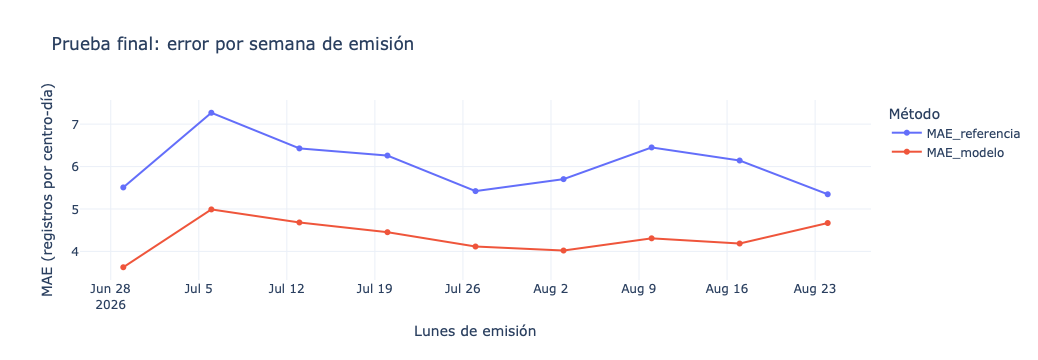

In [21]:
filas = []
for centro, grupo in observados_test.groupby(CENTRO):
    filas.append({CENTRO: centro,
                  "MAE_referencia": mean_absolute_error(grupo[OBJETIVO], grupo["pred_referencia"]),
                  "MAE_modelo": mean_absolute_error(grupo[OBJETIVO], grupo["pred_modelo"]),
                  "MAE_elegido": mean_absolute_error(grupo[OBJETIVO], grupo["pred_elegida"]),
                  "dias_evaluados": len(grupo), "registros_reales": int(grupo[OBJETIVO].sum())})
por_centro = pd.DataFrame(filas).sort_values("MAE_elegido", ascending=False)
por_horizonte = pd.DataFrame([
    {"horizonte_dias": int(h), **metricas(g[OBJETIVO], g["pred_elegida"])}
    for h, g in observados_test.groupby("horizonte_dias")
])
print("MAE macro por centro del método elegido:", round(por_centro["MAE_elegido"].mean(), 3))
display(por_centro.head(10).round(3))
display(por_horizonte.round(3))

fig_error = px.line(
    auditoria_test, x="origen", y=["MAE_referencia", "MAE_modelo"], markers=True,
    title="Prueba final: error por semana de emisión",
    labels={"origen": "Lunes de emisión", "value": "MAE (registros por centro-día)", "variable": "Método"}
)
fig_error.update_layout(template="plotly_white")
fig_error.show()
fig_error.write_html(SALIDA_INFORMES / "error_semanal_test.html", include_plotlyjs=True)

## 11. Comparar valores reales y estimados
Para que la figura sea legible, se muestra el centro con más días evaluados.
La serie se reindexa por fecha y conserva huecos sin objetivo; no se dibuja una línea que los oculte.

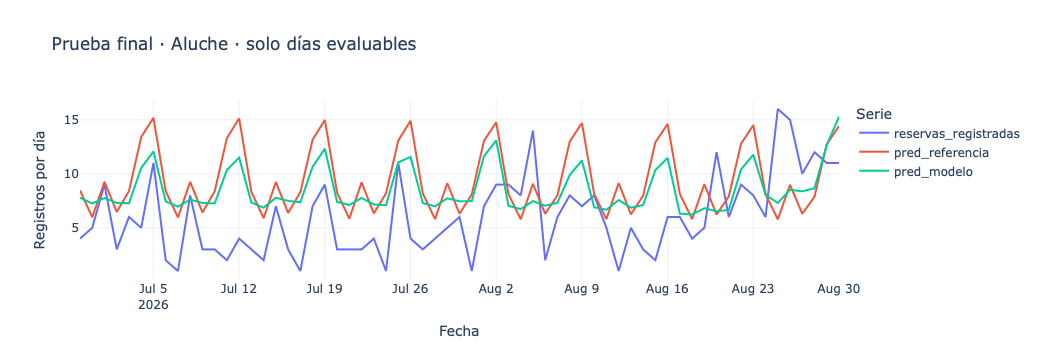

In [22]:
CENTRO_GRAFICO = por_centro.sort_values(
    ["dias_evaluados", CENTRO], ascending=[False, True]
).iloc[0][CENTRO]
grafico = observados_test.loc[observados_test[CENTRO] == CENTRO_GRAFICO].set_index("fecha")
grafico = grafico[[OBJETIVO, "pred_referencia", "pred_modelo"]].reindex(
    pd.date_range(INICIO_TEST, FIN_TEST, freq="D")
).rename_axis("fecha").reset_index()
fig_pred = px.line(
    grafico, x="fecha", y=[OBJETIVO, "pred_referencia", "pred_modelo"],
    title=f"Prueba final · {CENTRO_GRAFICO} · solo días evaluables",
    labels={"fecha": "Fecha", "value": "Registros por día", "variable": "Serie"}
)
fig_pred.update_traces(connectgaps=False)
fig_pred.update_layout(template="plotly_white")
fig_pred.show()
fig_pred.write_html(SALIDA_INFORMES / "reales_y_estimados_test.html", include_plotlyjs=True)

## 12. Ajuste final y demostración a siete días
Solo después de terminar la evaluación se ajusta con todo el histórico disponible.
La tabla resultante utiliza los siete días siguientes a la última fecha del CSV.
Con el histórico actual son **01/09/2026–07/09/2026**, no los siete días siguientes a hoy.
No se conocen aquí sus valores reales y no se les asigna un error de evaluación propio.

Se incluyen únicamente centros con el apoyo histórico fijado antes. Cada fila es una estimación
condicionada a que ese centro tenga registros ese día.

In [23]:
origen_final = diario["fecha"].max() + pd.Timedelta(days=1)
apoyo_final = apoyo_centros(diario, origen_final)
centros_finales = apoyo_final.loc[apoyo_final["elegible"], CENTRO].tolist()
if not centros_finales:
    raise ValueError("No hay centros con suficiente apoyo para la demostración.")
train_final = diario.loc[diario[CENTRO].isin(centros_finales)].copy()
referencia_final = ajustar_referencia(train_final)
modelo_final = construir_modelo()
with threadpool_limits(limits=2):
    modelo_final.fit(crear_X(train_final), train_final[OBJETIVO])

prevision = pd.MultiIndex.from_product(
    [centros_finales, pd.date_range(origen_final, periods=HORIZONTE, freq="D")],
    names=[CENTRO, "fecha"]
).to_frame(index=False)
prevision["pred_referencia"] = predecir_referencia(referencia_final, prevision)
with threadpool_limits(limits=2):
    prevision["pred_modelo"] = modelo_final.predict(crear_X(prevision))
prevision["estimacion_condicional"] = prevision[COLUMNA_ELEGIDA]
prevision["metodo_elegido"] = METODO_ELEGIDO
prevision["ultima_fecha_historica"] = diario["fecha"].max()
prevision["interpretacion"] = "Volumen estimado condicionado a un día con registros; no confirma apertura"
print("Periodo de demostración:", prevision["fecha"].min().date(), "—", prevision["fecha"].max().date())
print("Centros incluidos:", len(centros_finales))
print("Centros sin apoyo suficiente:", int((~apoyo_final["elegible"]).sum()))
display(
    prevision.head(14).round({
        "pred_referencia": 2,
        "pred_modelo": 2,
        "estimacion_condicional": 2
    })
)

Periodo de demostración: 2026-09-01 — 2026-09-07
Centros incluidos: 40
Centros sin apoyo suficiente: 5


,Centro deportivo,fecha,pred_referencia,pred_modelo,estimacion_condicional,metodo_elegido,ultima_fecha_historica,interpretacion
0,Adelfas,2026-09-01,3.39,5.77,5.77,modelo,2026-08-31,Volumen estimado condicionado a un día con reg...
1,Adelfas,2026-09-02,4.29,5.73,5.73,modelo,2026-08-31,Volumen estimado condicionado a un día con reg...
2,Adelfas,2026-09-03,3.91,5.77,5.77,modelo,2026-08-31,Volumen estimado condicionado a un día con reg...
3,Adelfas,2026-09-04,5.09,5.84,5.84,modelo,2026-08-31,Volumen estimado condicionado a un día con reg...
4,Adelfas,2026-09-05,8.30,9.35,9.35,modelo,2026-08-31,Volumen estimado condicionado a un día con reg...
5,Adelfas,2026-09-06,8.41,11.29,11.29,modelo,2026-08-31,Volumen estimado condicionado a un día con reg...
6,Adelfas,2026-09-07,3.90,5.92,5.92,modelo,2026-08-31,Volumen estimado condicionado a un día con reg...
7,Aluche,2026-09-01,5.90,9.40,9.40,modelo,2026-08-31,Volumen estimado condicionado a un día con reg...
8,Aluche,2026-09-02,9.06,9.63,9.63,modelo,2026-08-31,Volumen estimado condicionado a un día con reg...
9,Aluche,2026-09-03,6.35,9.45,9.45,modelo,2026-08-31,Volumen estimado condicionado a un día con reg...


## 13. Guardar el modelo y verificar su recarga
Se guarda un diccionario con el pipeline candidato, las medias de referencia, el método seleccionado,
las variables y las reglas de uso. No hay funciones o clases propias dentro del archivo joblib.
Las funciones `crear_X` y `predecir_referencia` de este notebook deberán reutilizarse al integrar Dash.

`modelo_diario.joblib` es un ajuste final; sus errores publicados proceden de los ajustes anteriores
de prueba, no de evaluarlo sobre sus propios datos de entrenamiento.
Utiliza archivos joblib propios y conserva las versiones de las dependencias al cargarlos.

In [24]:
paquete = {
    "version_formato": 1,
    "metodo_elegido": METODO_ELEGIDO,
    "pipeline_candidato": modelo_final,
    "referencia": referencia_final,
    "features": FEATURES,
    "centros_elegibles": centros_finales,
    "ultima_fecha_historica": diario["fecha"].max().strftime("%Y-%m-%d"),
    "horizonte_dias": HORIZONTE,
    "objetivo": "Registros por centro-día condicionados a que existan registros individuales",
    "versiones": versiones,
    "parametros": PARAMETROS,
    "reglas_apoyo": {"min_dias_historicos": MIN_DIAS_HISTORICOS,
                     "ventana_reciente": VENTANA_RECIENTE, "min_dias_recientes": MIN_DIAS_RECIENTES}
}
ruta_modelo = SALIDA_MODELOS / "modelo_diario.joblib"
joblib.dump(paquete, ruta_modelo, compress=3)
recargado = joblib.load(ruta_modelo)
if recargado["metodo_elegido"] == "modelo":
    with threadpool_limits(limits=2):
        pred_recargada = recargado["pipeline_candidato"].predict(crear_X(prevision))
else:
    pred_recargada = predecir_referencia(recargado["referencia"], prevision)
assert np.allclose(pred_recargada, prevision["estimacion_condicional"])
print("Modelo guardado y recarga comprobada:", ruta_modelo)

Modelo guardado y recarga comprobada: /home/202207424/TFG analytics/modelos/modelo_diario.joblib


## 14. Exportar resultados y conclusiones reproducibles

In [25]:
for nombre, tabla in {
    "predicciones_validacion.csv": pred_val,
    "predicciones_test.csv": pred_test,
    "auditoria_ventanas.csv": pd.concat([auditoria_val, auditoria_test], ignore_index=True),
    "metricas_validacion.csv": metricas_val.reset_index(),
    "metricas_test.csv": metricas_test.reset_index(),
    "errores_por_centro.csv": por_centro,
    "errores_por_horizonte.csv": por_horizonte,
    "apoyo_centros_final.csv": apoyo_final,
    "prevision_7_dias_condicional.csv": prevision
}.items():
    tabla.to_csv(SALIDA_DATOS / nombre, index=False, encoding="utf-8-sig")

sha256 = hashlib.sha256(RUTA_CSV.read_bytes()).hexdigest()
metadatos = {
    "archivo_entrada": "Datos/app/reservas_padel_app.csv", "sha256": sha256,
    "registros": len(reservas), "centros": int(diario[CENTRO].nunique()),
    "filas_diarias_observadas": len(diario), "versiones": versiones,
    "metodo_elegido_en_validacion": METODO_ELEGIDO,
    "validacion_inicio": str(INICIO_VALIDACION.date()), "test_inicio": str(INICIO_TEST.date()),
    "test_fin": str(FIN_TEST.date()), "horizonte_dias": HORIZONTE,
    "parametros": PARAMETROS, "reglas_apoyo": paquete["reglas_apoyo"],
    "metricas_validacion": metricas_val.to_dict(orient="index"),
    "metricas_test": metricas_test.to_dict(orient="index"),
    "supuesto_disponibilidad": "Histórico previo disponible al emitir; no se reproduce el retraso mensual de publicación",
    "tratamiento_ausencias": "Objetivo desconocido: sin imputación ni evaluación; predicción condicional"
}
(SALIDA_MODELOS / "metadatos_modelo.json").write_text(
    json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8"
)
requisitos = [f"{nombre}=={versiones[nombre]}" for nombre in ["numpy", "pandas", "scikit-learn", "joblib"]]
(SALIDA_MODELOS / "versiones_entrenamiento.txt").write_text("\n".join(requisitos) + "\n", encoding="utf-8")

mae_ref = metricas_test.loc["referencia", "MAE"]
mae_elegido = metricas_test.loc[METODO_ELEGIDO, "MAE"]
mejora = 100 * (mae_ref - mae_elegido) / mae_ref if mae_ref > 0 else float("nan")
conclusion = f"""# Conclusiones del primer modelo diario
Borja Ibáñez Pérez · ICAI

- Se agregaron {len(reservas):,} registros en {len(diario):,} filas centro-día observadas.
- El método seleccionado por el MAE de validación fue **{METODO_ELEGIDO}**.
- En prueba, el MAE de la referencia fue **{mae_ref:.3f}** registros por centro-día.
- El MAE del candidato HistGradientBoosting fue **{metricas_test.loc['modelo', 'MAE']:.3f}**.
- El método seleccionado obtuvo MAE **{mae_elegido:.3f}** y RMSE **{metricas_test.loc[METODO_ELEGIDO, 'RMSE']:.3f}**.
- Su reducción del MAE respecto a la referencia fue **{mejora:.2f}%** (negativo significa empeoramiento).
- Se evaluaron {len(observados_test):,} días-centro con objetivo observado; {int(pred_test[OBJETIVO].isna().sum()):,} combinaciones predichas no tenían objetivo y no entraron en las métricas.
- Se excluyeron {int(auditoria_test['dias_centro_observados_excluidos'].sum()):,} días-centro observados por insuficiente apoyo histórico en su origen.
- La evaluación reproduce ventanas de siete días con actualización semanal y selección del método anterior a la prueba.
- Los resultados son condicionales a días con registros y no miden ocupación, disponibilidad o demanda no satisfecha.
- La prueba abarca verano y hay menos de dos ciclos anuales; no puede suponerse el mismo error para otras estaciones.
- Se supone disponible el histórico anterior al origen; el retraso de publicación mensual no está modelado.
- La demostración corresponde a {prevision['fecha'].min().date()}–{prevision['fecha'].max().date()}, con {len(centros_finales)} centros elegibles. No es una previsión actualizada a la fecha de hoy.
- La integración en Dash y una posible ampliación horaria quedan pendientes.
"""
(SALIDA_INFORMES / "conclusiones_modelo.md").write_text(conclusion, encoding="utf-8")
display(Markdown(conclusion))
print("Resultados:", SALIDA_DATOS)
print("Modelo y metadatos:", SALIDA_MODELOS)
print("Gráficos e informe:", SALIDA_INFORMES)

# Conclusiones del primer modelo diario
Borja Ibáñez Pérez · ICAI

- Se agregaron 417,661 registros en 23,348 filas centro-día observadas.
- El método seleccionado por el MAE de validación fue **modelo**.
- En prueba, el MAE de la referencia fue **6.099** registros por centro-día.
- El MAE del candidato HistGradientBoosting fue **4.348**.
- El método seleccionado obtuvo MAE **4.348** y RMSE **5.625**.
- Su reducción del MAE respecto a la referencia fue **28.71%** (negativo significa empeoramiento).
- Se evaluaron 2,015 días-centro con objetivo observado; 666 combinaciones predichas no tenían objetivo y no entraron en las métricas.
- Se excluyeron 0 días-centro observados por insuficiente apoyo histórico en su origen.
- La evaluación reproduce ventanas de siete días con actualización semanal y selección del método anterior a la prueba.
- Los resultados son condicionales a días con registros y no miden ocupación, disponibilidad o demanda no satisfecha.
- La prueba abarca verano y hay menos de dos ciclos anuales; no puede suponerse el mismo error para otras estaciones.
- Se supone disponible el histórico anterior al origen; el retraso de publicación mensual no está modelado.
- La demostración corresponde a 2026-09-01–2026-09-07, con 40 centros elegibles. No es una previsión actualizada a la fecha de hoy.
- La integración en Dash y una posible ampliación horaria quedan pendientes.


Resultados: /home/202207424/TFG analytics/Datos/modelo
Modelo y metadatos: /home/202207424/TFG analytics/modelos
Gráficos e informe: /home/202207424/TFG analytics/informes/modelo
